## Process shapefiles
Create distance from the following drivers as quarter degree rasters, capping the values to a constant value at 400km distance
- Marine Protected Areas
- Piracy Events
- Distance from shore (capping at 200nm + 400km)

In [ ]:
import geopandas as gpd

i = 1
zipfile = f"data/raw/driver_data/marine-protected-areas/WDPA_Jul2026_Public_shp/WDPA_Jul2026_Public_shp_{i}.zip"
df = gpd.read_file(zipfile, columns=[])  # skip attribute columns, keep only geometry
df


In [ ]:
import gc
import numpy as np
import geopandas as gpd
from sklearn.neighbors import BallTree
from shapely import segmentize

df["geometry"] = df.geometry.buffer(0)  # fix invalid geometries

# densify polygon boundaries
df["geometry"] = df.geometry.apply(lambda geom: segmentize(geom, max_segment_length=0.25))

# Extract all boundary points from polygons
mpa_points = []
for geom in df.geometry:
    boundary = geom.boundary
    if boundary.geom_type == "LineString":
        coords = np.asarray(boundary.coords, dtype="float32")
    else:
        coords = np.vstack([np.asarray(line.coords) for line in boundary.geoms]).astype("float32")
    mpa_points.append(coords)
mpa_points = np.vstack(mpa_points)

del df
gc.collect()

mpa_points_rad = np.radians(mpa_points[:, [1, 0]])
del mpa_points
tree = BallTree(mpa_points_rad, metric="haversine")

# Build quarter-degree grid
xmin, ymin, xmax, ymax = -180, -90, 180, 90
res = 0.25
lon = np.arange(xmin + res/2, xmax, res)
lat = np.arange(ymax - res/2, ymin, -res)
lon_grid, lat_grid = np.meshgrid(lon, lat)

grid_points_rad = np.radians(
    np.vstack([lat_grid.ravel(), lon_grid.ravel()]).T
)

# Query nearest boundary point for every grid cell
dist_rad, _ = tree.query(grid_points_rad, k=1)
del tree, mpa_points_rad
gc.collect()
dist_km = dist_rad.ravel() * 6371.0088  # Earth radius in km

# Constant value beyond 400 km
dist_km = np.clip(dist_km, None, 400)

dist_raster = dist_km.reshape(lat_grid.shape).astype("float32")


In [ ]:
import rasterio
from rasterio.transform import from_origin

transform = from_origin(xmin, ymax, res, res)

out_meta = {
    "driver": "GTiff",
    "dtype": "float32",
    "height": dist_raster.shape[0],
    "width": dist_raster.shape[1],
    "count": 1,
    "crs": "EPSG:4326",
    "transform": transform,
    "nodata": np.nan,
    "compress": "lzw",
}

with rasterio.open(f"data/processed/mpa_distance{i}.tif", "w", **out_meta) as dst:
    dst.write(dist_raster, 1)

/tmp/ipykernel_47670/1708443511.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  data = src.read(1)


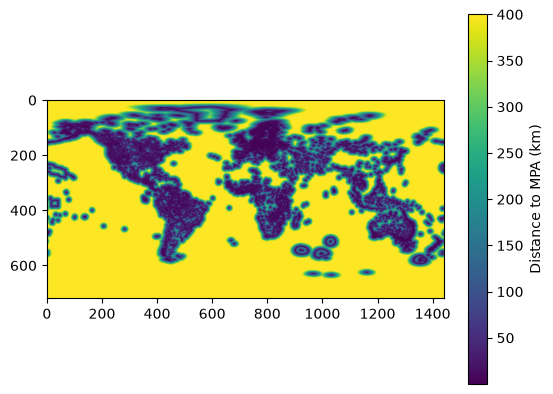

In [ ]:
import rasterio
import matplotlib.pyplot as plt

with rasterio.open(f"data/processed/mpa_distance{i}.tif") as src:
    data = src.read(1)

plt.imshow(data, cmap="viridis")
plt.colorbar(label="Distance to MPA (km)")
plt.show()